# Conditional KDE baseline

Este notebook organiza el baseline KDE condicional por calendario. El modelo usa un Autoencoder entrenado con `X_train`, ajusta KDEs en el espacio latente y aplica fallback jerarquico de calendario.

La seleccion de hiperparametros se hace exclusivamente con validation. Test se usa solamente despues, para reporte final de las configuraciones ya seleccionadas.

## Setup

In [1]:
from pathlib import Path
from types import SimpleNamespace
import json
import sys

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import Image, display

current_dir = Path.cwd().resolve()
if current_dir.name == "notebooks" and current_dir.parent.name == "provincias":
    provinces_root = current_dir.parent
elif current_dir.name == "provincias":
    provinces_root = current_dir
elif (current_dir / "provincias").exists():
    provinces_root = current_dir / "provincias"
else:
    raise RuntimeError("No se pudo ubicar la carpeta provincias")

src_dir = provinces_root / "src"
if str(src_dir) not in sys.path:
    sys.path.append(str(src_dir))

from conditional_kde_baseline import run_conditional_kde_baseline
from model_utils import (
    list_generation_plot_paths,
    load_calendar,
    load_result_table,
    load_x_splits,
    plot_metric_by_province,
    plot_month_metrics,
    plot_nrmse_by_province,
    plot_province_hour_heatmap,
    plot_training_history,
    print_split_checks,
    validate_x_splits,
)

splits_dir = provinces_root / "data" / "splits"
output_dir = provinces_root / "results" / "conditional_kde"
baseline_output_dir = provinces_root / "results" / "conditional_kde_baseline"
pretrained_autoencoder_path = baseline_output_dir / "autoencoder_best.pt"
if not pretrained_autoencoder_path.exists():
    pretrained_autoencoder_path = None

splits_dir, output_dir

(PosixPath('/Users/victoriapersico/Desktop/Ingenieria/Tercer Año/Machine Learning/TP_final/tp_final_ml/provincias/data/splits'),
 PosixPath('/Users/victoriapersico/Desktop/Ingenieria/Tercer Año/Machine Learning/TP_final/tp_final_ml/provincias/results/conditional_kde'))

## Datos de entrada

Se cargan solamente archivos de `provincias/data/splits/`. `X` ya esta escalado y los calendarios ya corresponden a los splits temporales definidos.

In [2]:
X = load_x_splits(splits_dir)
validate_x_splits(X)
print_split_checks(X)

calendar_train = load_calendar(splits_dir, "train")
calendar_val = load_calendar(splits_dir, "val")
calendar_test = load_calendar(splits_dir, "test")
display(calendar_train.head())
display(pd.DataFrame({
    "split": ["train", "val", "test"],
    "n_days": [len(calendar_train), len(calendar_val), len(calendar_test)],
    "start": [calendar_train["fecha"].min(), calendar_val["fecha"].min(), calendar_test["fecha"].min()],
    "end": [calendar_train["fecha"].max(), calendar_val["fecha"].max(), calendar_test["fecha"].max()],
}))

X_train: shape=(1457, 528), mean=0.0000, std=1.0000, nan_count=0
X_val: shape=(366, 528), mean=0.3081, std=1.1119, nan_count=0
X_test: shape=(485, 528), mean=0.4511, std=1.1791, nan_count=0


,fecha,mes,dia_semana,es_feriado
0,2019-01-01,1,1,1
1,2019-01-02,1,2,0
2,2019-01-03,1,3,0
3,2019-01-04,1,4,0
4,2019-01-05,1,5,0


,split,n_days,start,end
0,train,1457,2019-01-01,2023-12-31
1,val,366,2024-01-01,2024-12-31
2,test,485,2025-01-01,2026-04-30


## Ejecutar o cargar resultados

El analisis prueba `min_samples = [3, 5, 10, 15, 20]` y `bandwidth = [0.5, 0.75, 1.0, 1.25, 1.5, 2.0]`. Para cada combinacion se calculan log-likelihood y metricas generativas en validation. Test no se evalua dentro de esa grilla.

In [3]:
RUN_ANALYSIS = False

config = SimpleNamespace(
    splits_dir=splits_dir,
    output_dir=output_dir,
    pretrained_autoencoder_path=pretrained_autoencoder_path,
    seed=42,
    device="auto",
    latent_dim=16,
    hidden_dim=256,
    epochs=200,
    batch_size=64,
    learning_rate=1e-3,
    weight_decay=1e-5,
    patience=25,
    min_delta=1e-5,
    min_samples=20,
    min_samples_grid=[3, 5, 10, 15, 20],
    bandwidths=[0.5, 0.75, 1.0, 1.25, 1.5, 2.0],
    n_scenarios=500,
    mmd_max_samples=1000,
    plot_days=4,
    final_selection_criterion="validation_generative",
)

if RUN_ANALYSIS:
    display(run_conditional_kde_baseline(config))
else:
    print(f"Usando resultados guardados en {output_dir}")

Usando resultados guardados en /Users/victoriapersico/Desktop/Ingenieria/Tercer Año/Machine Learning/TP_final/tp_final_ml/provincias/results/conditional_kde


In [4]:
required_files = [
    output_dir / "config.json",
    output_dir / "autoencoder_history.csv",
    output_dir / "kde_min_samples_bandwidth_sensitivity.csv",
    output_dir / "kde_selection_comparison.csv",
    output_dir / "test_fallback_usage.csv",
    output_dir / "metrics_overall.csv",
    output_dir / "metrics_by_month.csv",
    output_dir / "metrics_by_province.csv",
    output_dir / "coverage_by_province_hour.csv",
    output_dir / "rmse_by_province_hour.csv",
]
missing_files = [path for path in required_files if not path.exists()]
if missing_files:
    raise FileNotFoundError(f"Faltan resultados. Cambiar RUN_ANALYSIS a True. Archivos: {missing_files}")

## Autoencoder

El Autoencoder define el espacio latente sobre el que se ajusta el KDE. La reconstruction loss se reporta en escala normalizada.

,value
bandwidths,"[0.5, 0.75, 1.0, 1.25, 1.5, 2.0]"
batch_size,64
best_bandwidth,2.0
best_min_samples,20
data_source,/Users/victoriapersico/Desktop/Ingenieria/Terc...
device,cpu
epochs,200
final_selection_criterion,validation_generative
hidden_dim,256
latent_dim,16


,split,reconstruction_mse_scaled
0,train,0.046317
1,val,0.097052
2,test,0.146215


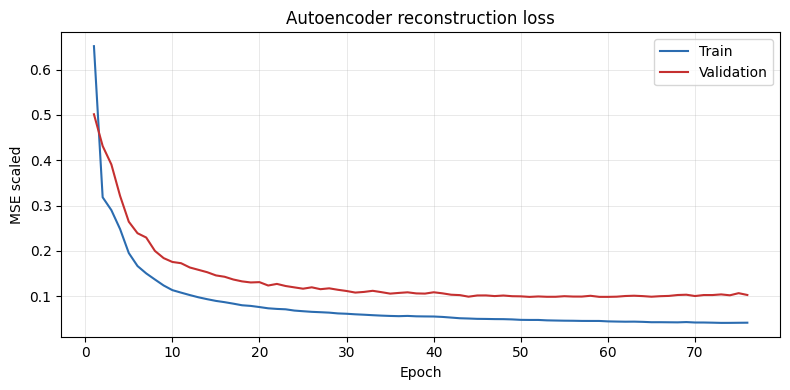

In [5]:
with open(output_dir / "config.json", "r", encoding="utf-8") as file:
    saved_config = json.load(file)

history = load_result_table(output_dir, "autoencoder_history.csv")
reconstruction_metrics = load_result_table(output_dir, "reconstruction_metrics.csv")
display(pd.Series(saved_config, name="value").to_frame())
display(reconstruction_metrics)
plot_training_history(history, "train_loss", "val_loss", "Autoencoder reconstruction loss", "MSE scaled")

## Sensibilidad en validation

El log-likelihood mide ajuste de densidad en el espacio latente. Coverage, sharpness, RMSE y MMD en validation estan mas alineadas con el objetivo final de generar escenarios utiles. Ninguna de estas filas usa test.

,min_samples,bandwidth,val_log_likelihood,val_coverage,val_sharpness,val_rmse_mean_profile,val_mmd,n_full,n_month_weekday,n_month,n_global,coverage_gap
0,20,1.50,-33.287754,0.881474,364.633571,252.643723,0.005353,0,0,366,0,0.018526
1,3,2.00,-33.823779,0.904527,357.485044,227.002609,0.006242,355,11,0,0,0.004527
2,10,2.00,-33.832160,0.904894,358.412148,227.968430,0.006373,351,15,0,0,0.004894
3,5,2.00,-33.832160,0.904894,358.412148,227.968430,0.006373,351,15,0,0,0.004894
4,15,2.00,-33.843279,0.904553,358.986180,229.188202,0.006096,324,42,0,0,0.004553
5,20,2.00,-33.846310,0.904454,393.464828,253.116959,0.006247,0,0,366,0,0.004454
6,3,1.50,-34.014320,0.878012,322.537379,226.226105,0.005357,355,11,0,0,0.021988
7,10,1.50,-34.019354,0.878472,323.648071,227.138840,0.005473,351,15,0,0,0.021528
8,5,1.50,-34.019354,0.878472,323.648071,227.138840,0.005473,351,15,0,0,0.021528
9,15,1.50,-34.030699,0.878312,324.391753,228.482132,0.005300,324,42,0,0,0.021688


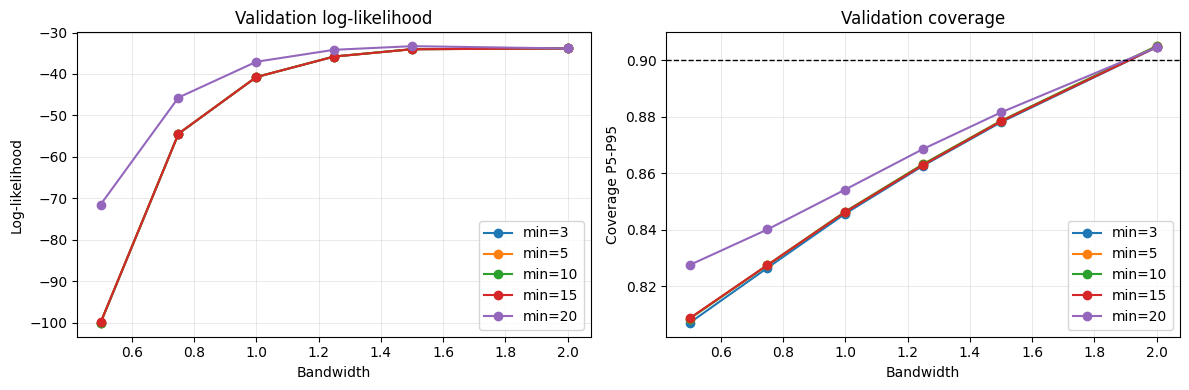

In [6]:
sensitivity = load_result_table(output_dir, "kde_min_samples_bandwidth_sensitivity.csv")
display(sensitivity.sort_values("val_log_likelihood", ascending=False))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for min_samples, group in sensitivity.groupby("min_samples"):
    ordered = group.sort_values("bandwidth")
    axes[0].plot(ordered["bandwidth"], ordered["val_log_likelihood"], marker="o", label=f"min={min_samples}")
    axes[1].plot(ordered["bandwidth"], ordered["val_coverage"], marker="o", label=f"min={min_samples}")
axes[0].set_title("Validation log-likelihood")
axes[0].set_xlabel("Bandwidth")
axes[0].set_ylabel("Log-likelihood")
axes[1].set_title("Validation coverage")
axes[1].set_xlabel("Bandwidth")
axes[1].set_ylabel("Coverage P5-P95")
axes[1].axhline(0.90, color="black", linestyle="--", linewidth=1)
for ax in axes:
    ax.grid(linewidth=0.4, alpha=0.5)
    ax.legend()
fig.tight_layout()
plt.show()

## Seleccion por validation y reporte en test

Se reportan dos configuraciones: la mejor por log-likelihood de validation y la mejor por criterio generativo de validation. El criterio generativo ordena por `coverage_gap = abs(val_coverage - 0.90)`, luego menor `val_sharpness` y luego menor `val_rmse_mean_profile`. Test aparece solo en esta tabla comparativa posterior.

In [7]:
selection_comparison = load_result_table(output_dir, "kde_selection_comparison.csv")
display(selection_comparison)

fallback_columns = ["selection_criterion", "n_full_test", "n_month_weekday_test", "n_month_test", "n_global_test"]
display(selection_comparison[fallback_columns])

generative_row = selection_comparison[selection_comparison["selection_criterion"] == "validation_generative"].iloc[0]
if generative_row["n_full_test"] + generative_row["n_month_weekday_test"] > generative_row["n_month_test"]:
    print("El criterio generativo selecciono grupos mas especificos; esto sugiere que el calendario fino aporta informacion.")
else:
    print("El criterio generativo tambien cae mayormente en fallback mensual; los grupos finos parecen inestables por pocas muestras.")

,selection_criterion,min_samples,bandwidth,val_log_likelihood,val_coverage,val_sharpness,val_rmse_mean_profile,val_mmd,test_coverage,test_sharpness,test_rmse_mean_profile,test_mmd,n_full_test,n_month_weekday_test,n_month_test,n_global_test
0,validation_log_likelihood,20,1.5,-33.287754,0.881474,364.633571,252.643723,0.005353,0.871774,376.864675,253.123978,0.009581,0,0,485,0
1,validation_generative,20,2.0,-33.846310,0.904454,393.464828,253.116959,0.006247,0.894037,404.342024,253.101471,0.008879,0,0,485,0


,selection_criterion,n_full_test,n_month_weekday_test,n_month_test,n_global_test
0,validation_log_likelihood,0,0,485,0
1,validation_generative,0,0,485,0


El criterio generativo tambien cae mayormente en fallback mensual; los grupos finos parecen inestables por pocas muestras.


## Evaluacion final de la configuracion elegida

Las metricas siguientes corresponden a la configuracion final guardada, elegida por criterio generativo de validation. Test funciona aqui solo como evaluacion final.

In [8]:
overall_metrics = load_result_table(output_dir, "metrics_overall.csv")
display(overall_metrics.T.rename(columns={0: "value"}))

row = overall_metrics.iloc[0]
print(f"Coverage P5-P95: {row['coverage_p5_p95']:.3f}")
print(f"Sharpness promedio P5-P95: {row['sharpness_p5_p95_mwh']:.2f} MWh")
print(f"RMSE del perfil medio: {row['mean_profile_rmse_mwh']:.2f} MWh")
print(f"MMD RBF: {row['mmd_rbf']:.6f}")

,value
coverage_p5_p95,0.894037
sharpness_p5_p95_mwh,404.342024
mean_profile_rmse_mwh,253.101471
mmd_rbf,0.008879
n_days,485.000000
n_scenarios_per_day,500.000000


Coverage P5-P95: 0.894
Sharpness promedio P5-P95: 404.34 MWh
RMSE del perfil medio: 253.10 MWh
MMD RBF: 0.008879


## Evaluacion por mes, provincia y hora

,mes,coverage,sharpness,rmse_mean_profile,n_days
0,1,0.923082,473.048588,299.146454,62
1,2,0.751082,458.344201,307.739136,56
2,3,0.896566,503.900720,290.662445,62
3,4,0.915878,311.415283,149.984009,60
4,5,0.946786,347.712583,260.539307,31
5,6,0.930997,396.529683,233.582932,30
6,7,0.867241,372.792478,254.072784,31
7,8,0.938416,345.911042,210.160583,31
8,9,0.899874,332.765809,190.597534,30
9,10,0.924976,338.117267,143.027283,31


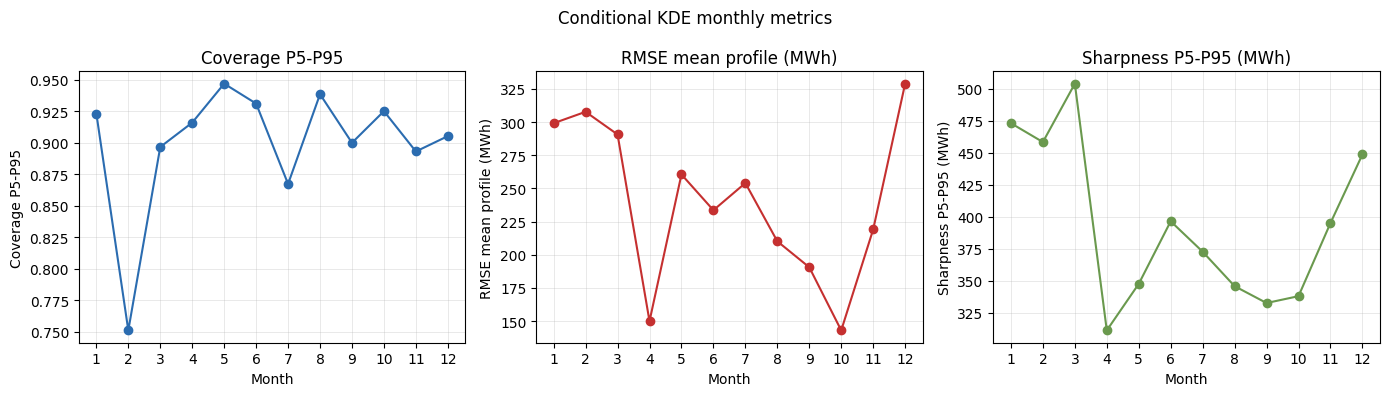

,province,rmse,mean_profile_rmse_mwh,mean_demand,mean_demand_mwh,nrmse,coverage,coverage_p5_p95,sharpness,sharpness_p5_p95_mwh,mmd_rbf
20,sgo_del_estero,75.102959,75.102959,241.469025,241.469025,0.311025,0.874055,0.874055,188.459397,188.459397,0.035988
2,chaco,106.108963,106.108963,401.316223,401.316223,0.264402,0.890550,0.890550,313.485923,313.485923,0.020922
7,formosa,45.536964,45.536964,184.996826,184.996826,0.246150,0.894674,0.894674,147.850956,147.850956,0.020005
5,corrientes,81.292625,81.292625,375.334198,375.334198,0.216587,0.894931,0.894931,236.216233,236.216233,0.017375
21,tucuman,82.745277,82.745277,392.474487,392.474487,0.210830,0.914433,0.914433,243.311869,243.311869,0.017885
16,san_juan,55.918331,55.918331,285.251984,285.251984,0.196031,0.928608,0.928608,174.294583,174.294583,0.012979
1,catamarca,31.296337,31.296337,164.645828,164.645828,0.190083,0.873454,0.873454,85.738159,85.738159,0.051180
10,la_rioja,34.664970,34.664970,186.800217,186.800217,0.185572,0.907131,0.907131,108.169982,108.169982,0.011139


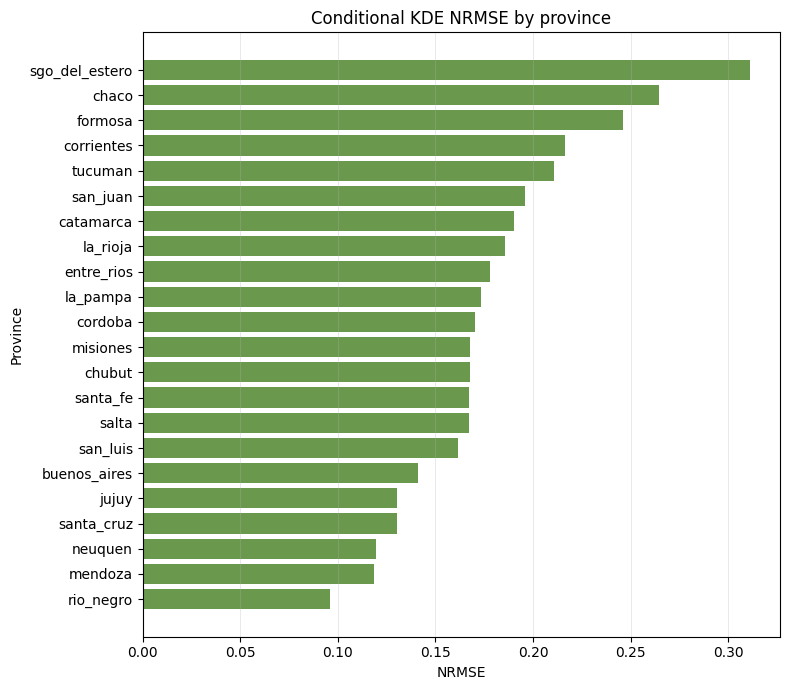

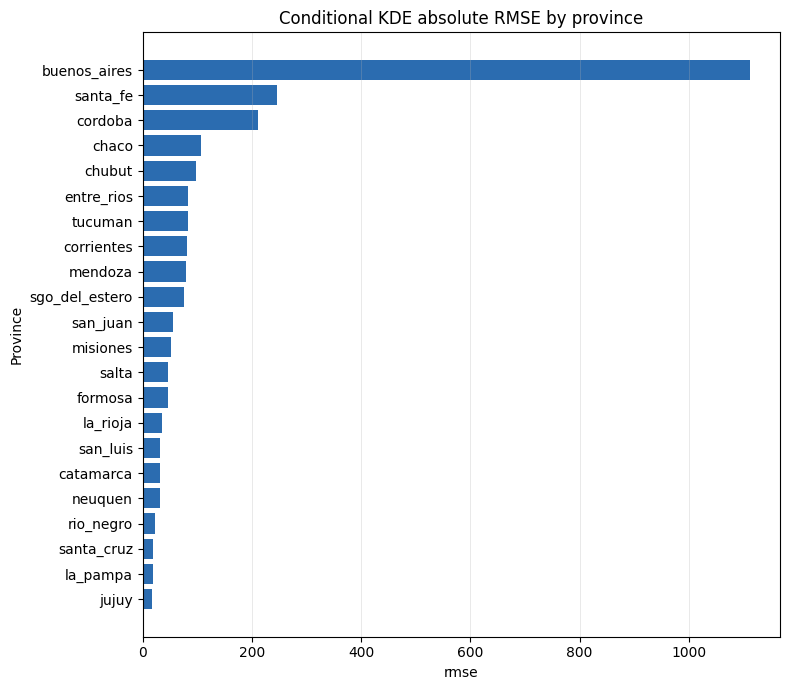

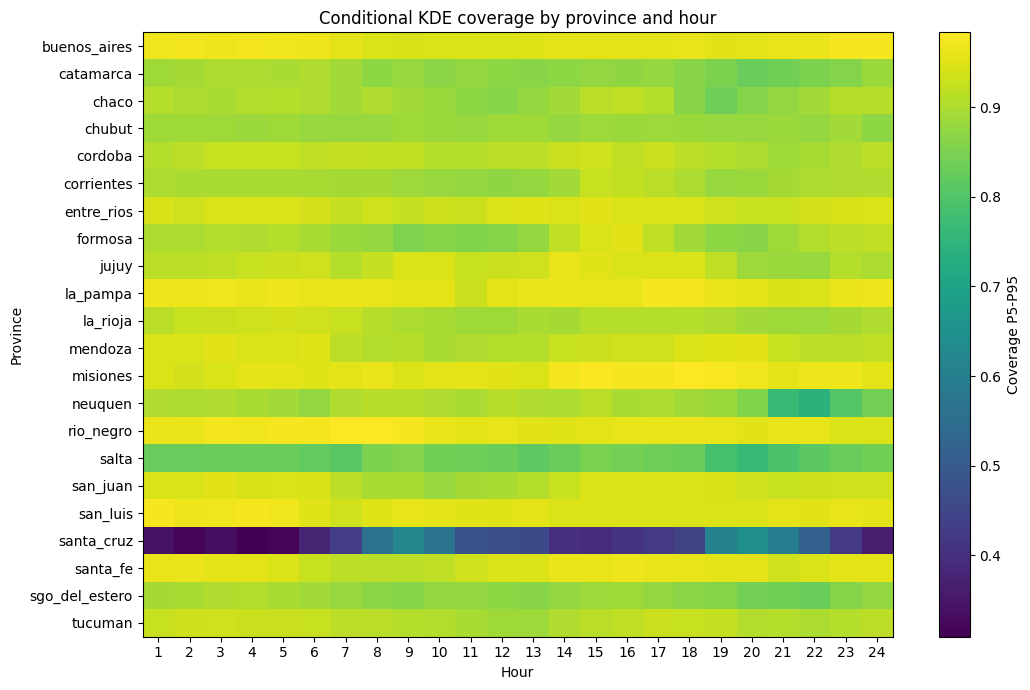

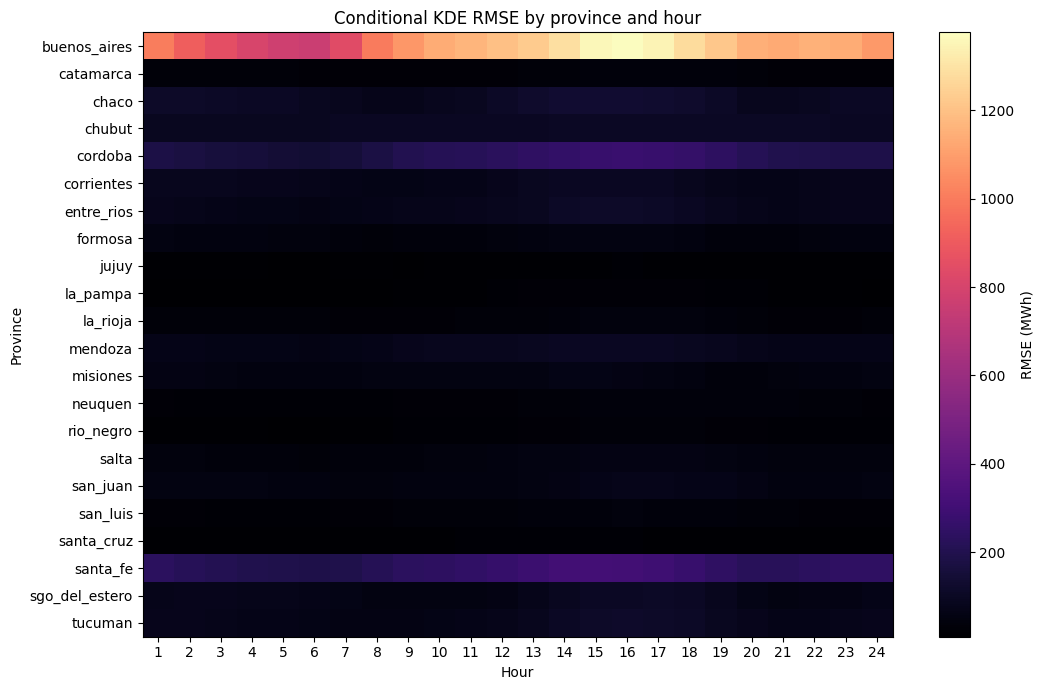

In [9]:
metrics_by_month = load_result_table(output_dir, "metrics_by_month.csv")
province_metrics = load_result_table(output_dir, "metrics_by_province.csv")
coverage_by_hour = pd.read_csv(output_dir / "coverage_by_province_hour.csv", index_col=0)
rmse_by_hour = pd.read_csv(output_dir / "rmse_by_province_hour.csv", index_col=0)

display(metrics_by_month)
plot_month_metrics(metrics_by_month, "Conditional KDE monthly metrics")
display(province_metrics.sort_values("nrmse", ascending=False).head(8))
plot_nrmse_by_province(province_metrics, "Conditional KDE NRMSE by province")
plot_metric_by_province(province_metrics, "rmse", "Conditional KDE absolute RMSE by province")
plot_province_hour_heatmap(coverage_by_hour, "Conditional KDE coverage by province and hour", "Coverage P5-P95", "viridis")
plot_province_hour_heatmap(rmse_by_hour, "Conditional KDE RMSE by province and hour", "RMSE (MWh)", "magma")

## Perfiles reales vs generados

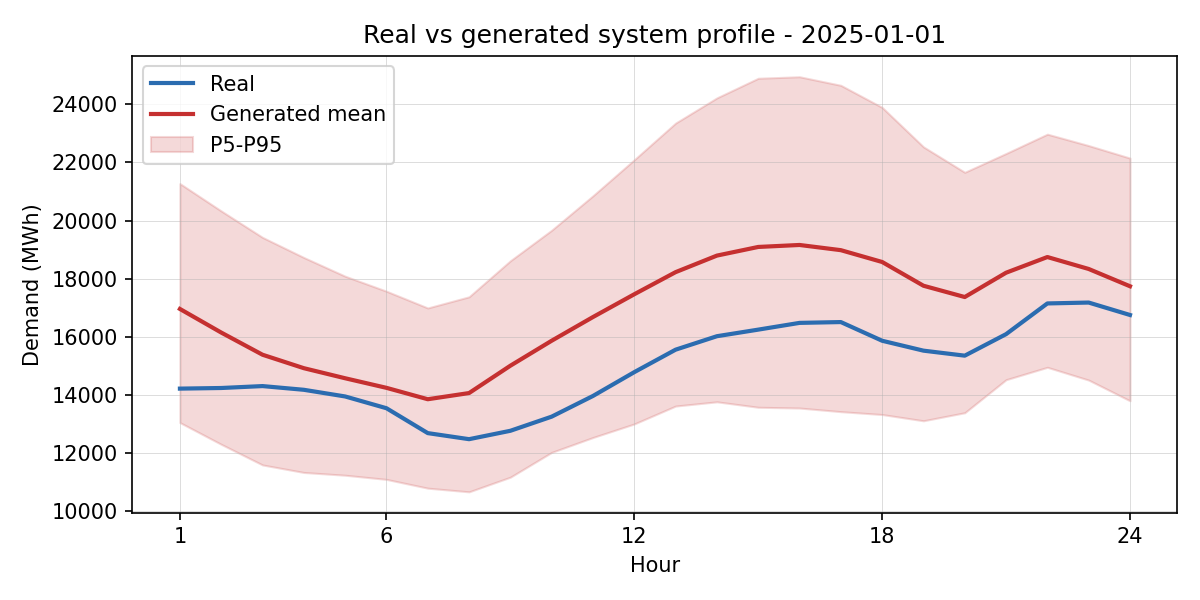

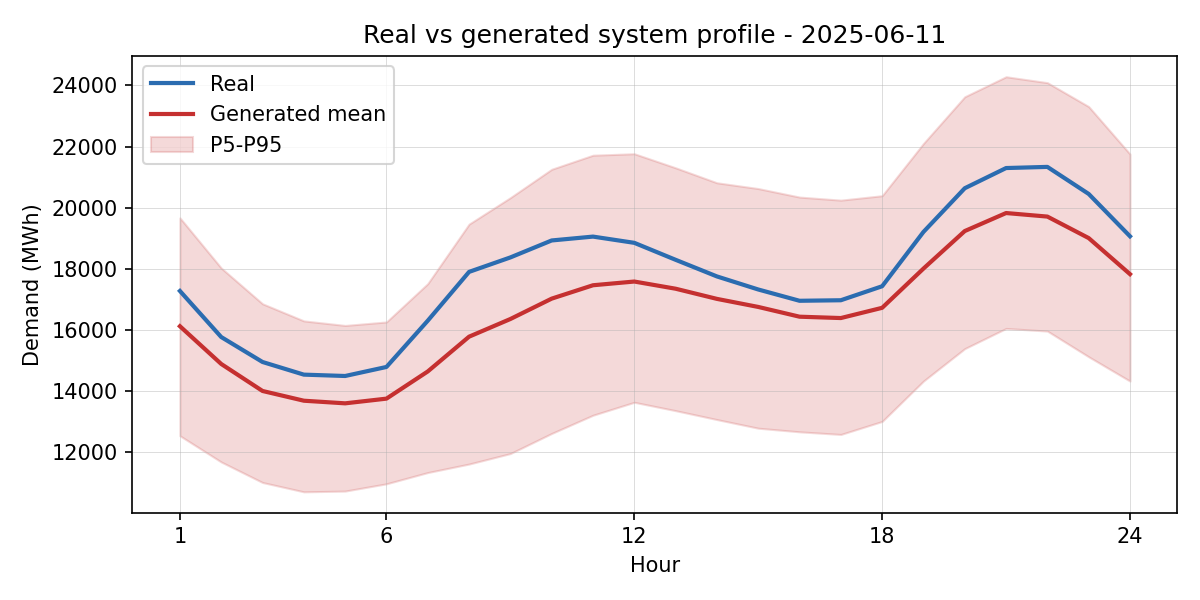

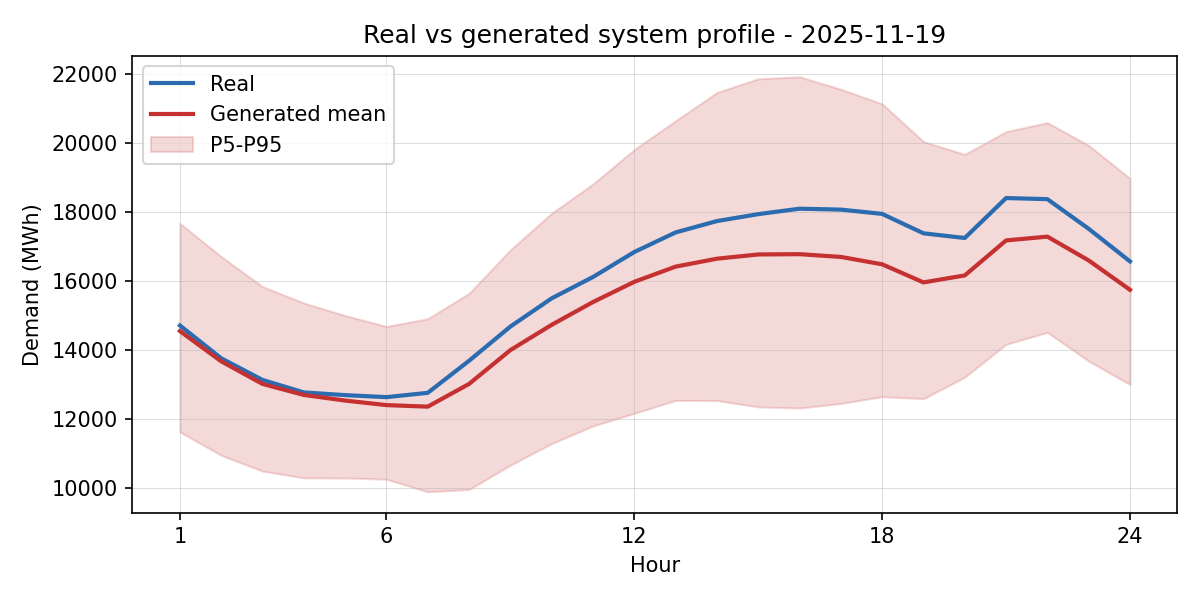

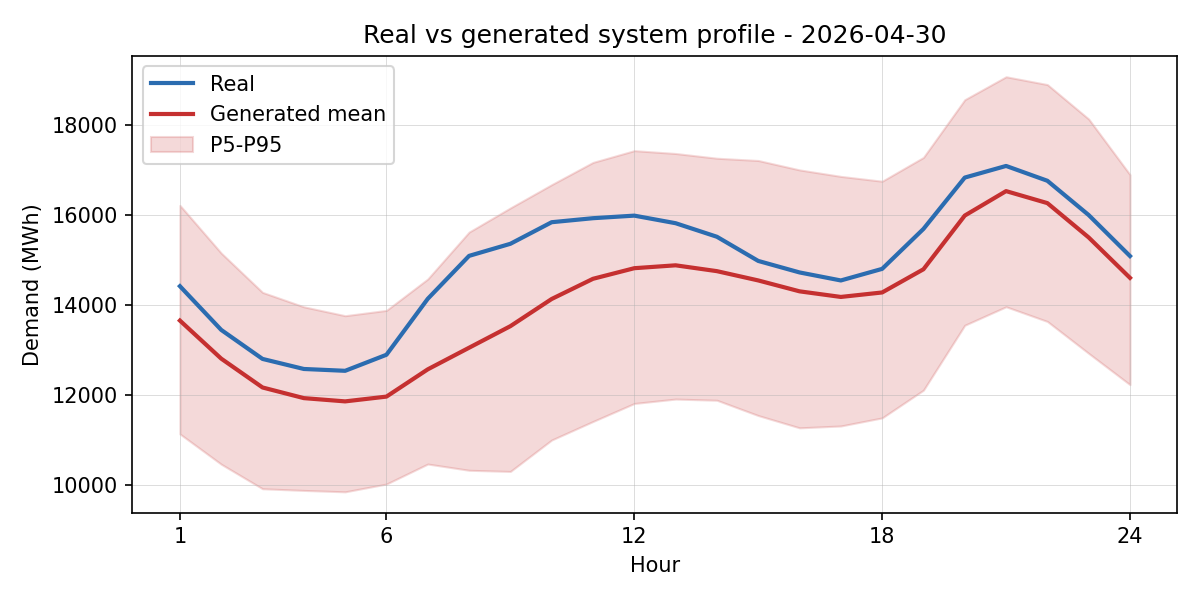

In [10]:
for plot_path in list_generation_plot_paths(output_dir, max_plots=4):
    display(Image(filename=str(plot_path)))

## Conclusion

La seleccion por log-likelihood prioriza ajuste de densidad latente, mientras que la seleccion generativa usa metricas mas cercanas al objetivo del TP: cobertura, nitidez y error del perfil medio. Ambas decisiones se toman con validation. En esta corrida, la seleccion generativa queda guardada como configuracion final y test se usa solo para medirla. El fallback observado permite interpretar si el KDE aprovecha calendario fino o si en la practica se comporta como un modelo mensual.